In [56]:
get_ipython().run_line_magic('reset', '-f')

In [57]:
import os
import re
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
import statsmodels.api as sm
from scipy.stats import mannwhitneyu, spearmanr
from sklearn.metrics import roc_auc_score, roc_curve
import seaborn as sns

In [ ]:
# ─────────────────────────────────────────────
# CONFIG – adjust these to match the setup
# ─────────────────────────────────────────────

# Fixed trajectory folder (relative to this notebook location).
TRAJ_DIR = "../Result_Files/Sphere/Quant_Files/"
TRAJ_GLOB = "trajectory_*_s_*_Run_*"

# Column index -> feature name (0-based)
COLUMN_MAP = {
    0:  "Time",
    1:  "NumCells",
    2:  "CellID",
    3:  "x",
    4:  "y",
    5:  "z",
    6:  "ori_x",
    7:  "ori_y",
    8:  "ori_z",
    9:  "radius",
    10: "cell_type",
    11: "living_status",
    12: "GERM",
    13: "S_nbd",
    14: "NURSE_CELL_ACTIVATION",
    15: "GERM_mRNA1",
    16: "GERM_mRNA2",
    17: "GERM_P1",
    18: "GERM_P2",
    19: "DONOR_CELL",
    20: "TOTAL_GERM_NBD_COUNT",
    21: "TOTAL_SOMATIC_NBD_COUNT",
}

In [59]:
# ─────────────────────────────────────────────
# Parse filename parameters
# ─────────────────────────────────────────────

def parse_filename_params(path: str) -> dict | None:
    """
    Extract key/value parameters from trajectory filenames.

    Supports both legacy and extended names, e.g.:
      trajectory_sphere_s_PTN_..._ESC_..._A_..._B_..._Run_1(.txt)
      trajectory_cylinder_s_PTN_..._..._SF_..._i22_..._Run_18(.txt)

    Returns None if the filename does not match the expected pattern.
    """
    stem = Path(path).stem  # handles optional .txt suffix
    pattern = r"^trajectory_(?P<Geometry>[^_]+)_s_(?P<body>.+)_Run_(?P<Run>\d+)$"
    m = re.match(pattern, stem)
    if m is None:
        return None

    params = {
        "Geometry": m.group("Geometry"),
        "Run": int(m.group("Run")),
    }

    body = m.group("body")
    tokens = body.split("_")

    # Parse alternating KEY_VALUE tokens: PTN_16.25_ESC_60.33_...
    # If malformed tail exists, ignore the final orphan token.
    n = len(tokens) - (len(tokens) % 2)
    for i in range(0, n, 2):
        key = tokens[i]
        raw_val = tokens[i + 1]

        if not key:
            continue

        try:
            val = float(raw_val)
        except ValueError:
            val = raw_val

        params[key] = val

    # Keep legacy downstream compatibility even if some keys are missing.
    for k in ("PTN", "ESC", "A", "B"):
        params.setdefault(k, np.nan)

    return params

In [60]:
# column index in the trajectory file -> stored feature name
STORE_COLS = {
    9:  "radius",
    12: "GERM", 13: "S_nbd", 14: "NURSE_CELL_ACTIVATION",
    15: "GERM_mRNA1", 16: "GERM_mRNA2", 17: "GERM_P1", 18: "GERM_P2",
    19: "DONOR_CELL", 20: "TOTAL_GERM_NBD_COUNT", 21: "TOTAL_SOMATIC_NBD_COUNT",
}
_MIN_TOKENS = 22


def _list_files(traj_dir, traj_glob, max_files):
    files = sorted(glob.glob(os.path.join(traj_dir, traj_glob)))
    if max_files is not None:
        if max_files <= 0:
            raise ValueError("max_files must be None or a positive integer")
        files = files[:max_files]
    return files


def _parse_run(path, cols):
    """Parse one trajectory file -> float32 array [time, cell, <cols...>] (no DataFrame)."""
    use = [0, 2] + list(cols)
    rows = []
    with open(path) as f:
        for line in f:
            if not line or line[0] in "!#$\n":
                continue
            p = line.split()
            if len(p) < _MIN_TOKENS:
                continue
            try:
                rows.append([float(p[i]) for i in use])
            except ValueError:              
                continue
    return np.asarray(rows, dtype=np.float32)


def load_cube(traj_dir=TRAJ_DIR, traj_glob=TRAJ_GLOB, max_files=None,
              ref_radius=None, dtype=np.float32):
    """
    Read all trajectory files into a cube.
    Replaces:  load_all_trajectories + add_relative_volume (relative_volume is added here).
    Pass ref_radius=5.2 to use an explicit reference radius (else first GERM cell radius).
    """
    files = _list_files(traj_dir, traj_glob, max_files)
    print(f"Found {len(files)} trajectory files in {traj_dir}")
    if not files:
        return None

    #  universe of cell ids and times, run ids
    cells_u, times_u, runs, keep = set(), set(), [], []
    for fp in files:
        params = parse_filename_params(fp)
        if params is None:
            
            
            
            (f"Skipping (name mismatch): {Path(fp).name}")
            continue
        with open(fp) as f:
            for line in f:
                if not line or line[0] in "!#$\n":
                    continue
                tok = line.split(None, 3)
                if len(tok) < 3:
                    continue
                try:
                    cells_u.add(int(tok[2]))
                    times_u.add(round(float(tok[0]), 6))
                except ValueError:
                    continue
        runs.append(params["Run"]); keep.append(fp)
    cells = np.array(sorted(cells_u)); times = np.array(sorted(times_u))

    feats = list(STORE_COLS.values()) + ["relative_volume"]
    data = np.full((len(feats), len(keep), len(cells), len(times)), np.nan, dtype=dtype)
    r0 = ref_radius

    #  fill the cube one run at a time
    for r, fp in enumerate(keep):
        a = _parse_run(fp, STORE_COLS)
        if a.size == 0:
            continue
        ci = np.searchsorted(cells, a[:, 1].astype(np.int64))
        ti = np.searchsorted(times, np.round(a[:, 0].astype(np.float64), 6))
        for k in range(len(STORE_COLS)):
            data[k, r, ci, ti] = a[:, 2 + k]
        if r0 is None:                                   
            g = a[a[:, 2 + list(STORE_COLS.values()).index("GERM")] == 1.0]
            if len(g):
                r0 = float(g[0, 2 + list(STORE_COLS.values()).index("radius")])
        del a, ci, ti

    cube = {"data": data, "features": feats, "runs": np.array(runs), "cells": cells,
            "times": times, "r0": r0, "files": keep}
    mb = data.nbytes / 1e6
    print(f"Cube: {len(keep)} runs x {len(cells)} cells x {len(times)} times x {len(feats)} features "
          f"= {mb:.0f} MB")
    return cube


def _feat(cube, name):
    """View of one feature, shape (runs, cells, times)."""
    return cube["data"][cube["features"].index(name)]

In [61]:
# ═════════════════════════════════════════════════════════════════════════════
# Nurse-cell probability vs initial S_nbd
# ═════════════════════════════════════════════════════════════════════════════

NURSE_VALUE = 10.0

def build_fate_table_all_runs(cube, t_init=None):
    """
    One row per (Run, germ cell): S0, nurse, t_activation, reversals (10 -> 0).
    S0 = S_nbd at the first time S_nbd differs across germ cells (true initialisation),
    unless t_init is given.
    """
    times, cells, runs = cube["times"], cube["cells"], cube["runs"]
    germ = np.nanmax(_feat(cube, "GERM"), axis=(0, 2)) == 1.0
    S, A = _feat(cube, "S_nbd")[:, germ], _feat(cube, "NURSE_CELL_ACTIVATION")[:, germ]
    gcells = cells[germ]
    rows = []
    for r, run in enumerate(runs):
        s = S[r]
        if t_init is None:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore", category=RuntimeWarning)
                spread = np.nanmax(s, axis=0) - np.nanmin(s, axis=0)
            idx = np.nonzero(spread > 0)[0]
            j0 = idx[0] if len(idx) else None
        else:
            j0 = int(np.argmin(np.abs(times - t_init)))
        for c, cid in enumerate(gcells):
            a_row, s_row = A[r, c], s[c]
            ok = np.isfinite(a_row)
            if not ok.any():
                continue
            act = a_row[ok] >= NURSE_VALUE
            t_ok = times[ok]
            rows.append({"Run": int(run), "CellID": int(cid),
                         "S0": float(s_row[j0]) if j0 is not None else np.nan,
                         "nurse": int(act.any()),
                         "t_activation": float(t_ok[act][0]) if act.any() else np.nan,
                         "reversals": int((act[:-1] & ~act[1:]).sum())})
    fate = pd.DataFrame(rows).dropna(subset=["S0"])
    assert fate.groupby("CellID").S0.nunique().max() == 1, "a cell has different S0 in different runs"
    return fate

In [62]:
cube = load_cube(TRAJ_DIR, max_files=100)                 # or ref_radius=5.2
GERM_CELL_RADIUS = cube["r0"]                          

Found 35 trajectory files in ../Result_Files_Final/Sphere/Quant_Files/
Cube: 35 runs x 160 cells x 481 times x 12 features = 129 MB


In [63]:
def plot_fate_raster_and_ranking(
    fate,
    out_dir=None,
    show=True,
    dpi=300,
    figsize=(24, 12),
    axis_fontsize=32,
    tick_fontsize=24,
    cell_fontsize=24,
):
    """
    Two-panel descriptive figure, without legends or a colour bar.

    A: Fate of each cell in each run; rows sorted by initial S_nbd,
       then by  nurse probability.
    B: Cells ranked by  nurse probability; point colour
       represents initial S_nbd using viridis.

    Requires one row per (Run, CellID) and a constant S0 per cell.
    """
    required = ["Run", "CellID", "S0", "nurse"]
    missing = [column for column in required if column not in fate.columns]

    if missing:
        raise ValueError(f"Missing required columns: {missing}")

    if fate.empty:
        raise ValueError("The fate table is empty.")

    if fate[required].isna().any().any():
        raise ValueError("Required columns contain missing values.")

    if fate.duplicated(["Run", "CellID"]).any():
        raise ValueError(
            "Expected one row per (Run, CellID), but duplicates were found."
        )

    if not fate["nurse"].isin([0, 1]).all():
        raise ValueError("'nurse' must contain only 0 and 1.")

    if (fate.groupby("CellID")["S0"].nunique() > 1).any():
        raise ValueError(
            "Some cells have different initial S_nbd values across runs. "
            "Check the initialization before making this figure."
        )

    font_settings = {
        "font.family": "serif",
        "font.serif": ["Times New Roman"],
        "mathtext.fontset": "stix",
    }

    with plt.rc_context(font_settings):
        # One  probability per cell.
        per_cell = (
            fate.groupby("CellID", as_index=False)
            .agg(
                S0=("S0", "first"),
                k=("nurse", "sum"),
                n=("nurse", "size"),
            )
        )
        per_cell["p_nurse"] = per_cell["k"] / per_cell["n"]

        order = per_cell.sort_values(
            ["S0", "p_nurse", "CellID"]
        ).reset_index(drop=True)

        raster = (
            fate.pivot(index="CellID", columns="Run", values="nurse")
            .reindex(index=order["CellID"])
            .sort_index(axis=1)
        )

        if raster.isna().any().any():
            raise ValueError(
                "Some cells are missing outcomes for some runs. "
                "Missing outcomes must not be plotted as non-nurse."
            )

        norm = plt.Normalize(
            vmin=per_cell["S0"].min(),
            vmax=per_cell["S0"].max(),
        )

        fig, (axA, axB) = plt.subplots(
            1,
            2,
            figsize=figsize,
            gridspec_kw={"width_ratios": [1.15, 1]},
            layout="constrained",
        )

        # ================= A: cell run 35X32 =================
        sns.heatmap(
            raster,
            cmap=["#f0f4f8", "steelblue"],
            vmin=0,
            vmax=1,
            cbar=False,
            ax=axA,
            linewidths=0.2,
            linecolor="white",
            xticklabels=False,
            yticklabels=False,
        )

        axA.set_yticks(np.arange(len(order)) + 0.5)
        axA.set_yticklabels(
            [
                f"{int(cid)}  ({s0:.2f})"
                for cid, s0 in zip(order["CellID"], order["S0"])
            ],
            rotation=0,
        )

        # Display actual run IDs, including the final run.
        n_runs = raster.shape[1]
        run_ticks = np.unique(
            np.r_[np.arange(0, n_runs, 5), n_runs - 1]
        )
        axA.set_xticks(run_ticks + 0.5)
        axA.set_xticklabels(
            [str(raster.columns[i]) for i in run_ticks],
            rotation=0,
        )

        axA.set_xlabel(
            "Simulation run",
            fontsize=axis_fontsize,
            fontweight="bold",
            fontfamily="Times New Roman",
        )
        axA.set_ylabel(
            r"Cell ID (Initial $S_{nbd}$)",
            fontsize=axis_fontsize,
            fontweight="bold",
            fontfamily="Times New Roman",
        )

        # More compact row labels to accommodate all 32 cells.
        axA.tick_params(
            axis="x",
            labelsize=tick_fontsize,
            length=6,
            width=1.2,
        )
        axA.tick_params(
            axis="y",
            labelsize=cell_fontsize,
            length=0,
        )

        # ================= B: ranked cells =================
        ranked = per_cell.sort_values(
            ["p_nurse", "S0", "CellID"]
        ).reset_index(drop=True)

        ranks = np.arange(1, len(ranked) + 1)

        sc = axB.scatter(
            ranks,
            ranked["p_nurse"],
            c=ranked["S0"],
            cmap="viridis",
            norm=norm,
            s=100,
            edgecolor="black",
            linewidth=0.6,
            zorder=3,
        )

        cbar = fig.colorbar(sc, ax=axB, pad=0.02, fraction=0.05)
        cbar.set_label(
            r"Initial $S_{nbd}$",
            fontsize=axis_fontsize,
            fontweight="bold",
            fontfamily="Times New Roman",
        )
        cbar.ax.tick_params(labelsize=tick_fontsize, length=6, width=1.2)
        for label in cbar.ax.get_yticklabels():
            label.set_fontfamily("Times New Roman")
        cbar.outline.set_linewidth(1.2)


        axB.set_xlabel(
            "Cell rank",
            fontsize=axis_fontsize,
            fontweight="bold",
            fontfamily="Times New Roman",
        )
        axB.set_ylabel(
            r"Nurse-fate probability, $P(\mathrm{nurse})$",
            fontsize=axis_fontsize,
            fontweight="bold",
            fontfamily="Times New Roman",
        )

        axB.tick_params(
            axis="both",
            labelsize=tick_fontsize,
            length=6,
            width=1.2,
        )
        axB.set_ylim(-0.03, 1.05)
        axB.set_yticks(np.arange(0, 1.01, 0.2))
        axB.set_xlim(0.3, len(ranked) + 0.7)

        rank_ticks = np.unique(
            np.r_[1, np.arange(5, len(ranked) + 1, 5), len(ranked)]
        )
        axB.set_xticks(rank_ticks)

        axB.grid(
            True,
            alpha=0.3,
            linestyle=":",
            linewidth=0.8,
        )

        # Panel labels only; explanations are in the caption.
        for ax, panel in zip((axA, axB), ("A", "B")):
            ax.set_title(
                panel,
                loc="left",
                fontsize=32,
                fontweight="bold",
                fontfamily="Times New Roman",
                pad=15,
            )

            for label in ax.get_xticklabels() + ax.get_yticklabels():
                label.set_fontfamily("Times New Roman")

            for spine in ax.spines.values():
                spine.set_linewidth(1.2)

        if out_dir:
            os.makedirs(out_dir, exist_ok=True)
            stem = os.path.join(out_dir, "fate_overiew_two_panels")

            fig.savefig(
                stem + ".png",
                dpi=dpi,
                bbox_inches="tight",
            )
            fig.savefig(
                stem + ".pdf",
                bbox_inches="tight",
            )

        if show:
            plt.show()

        plt.close(fig)

    return per_cell

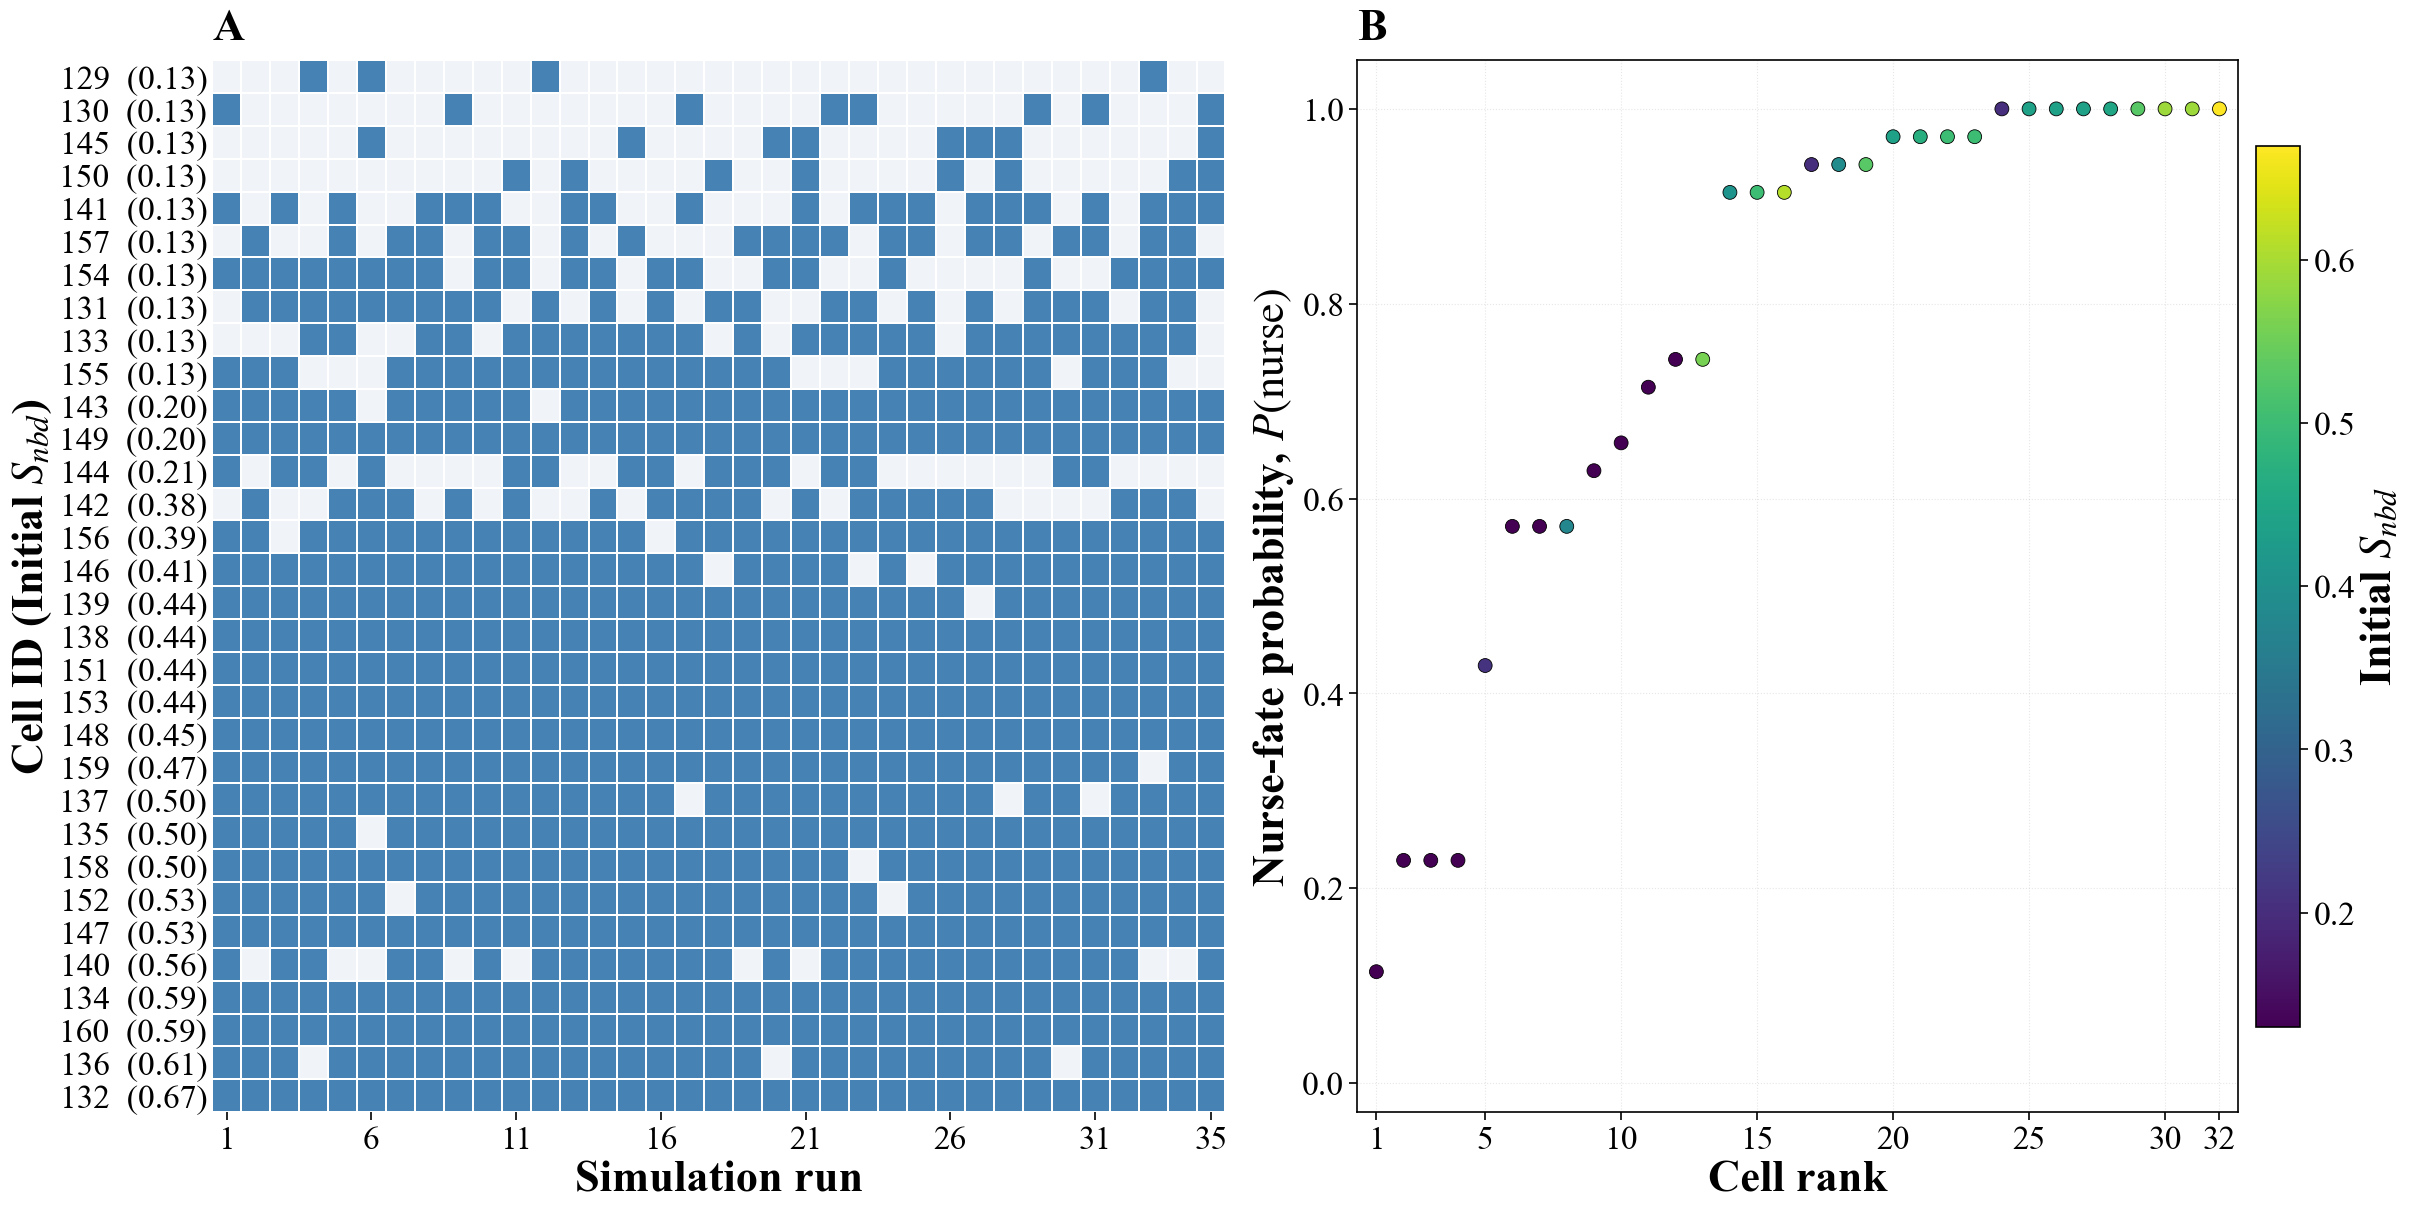

,CellID,S0,k,n,p_nurse
0,129,0.13,4,35,0.114286
1,130,0.13,8,35,0.228571
2,131,0.13,23,35,0.657143
3,132,0.67,35,35,1.000000
4,133,0.13,25,35,0.714286
5,134,0.59,35,35,1.000000
6,135,0.50,34,35,0.971429
7,136,0.61,32,35,0.914286
8,137,0.50,32,35,0.914286
9,138,0.44,35,35,1.000000


In [64]:
fate = build_fate_table_all_runs(cube, t_init=0.0)
plot_fate_raster_and_ranking(fate, out_dir="output",    show=True, dpi=300,)